## Kmeans First Run
### Purpose:
Exploration: Learn The data, try k-means once, look at plot

In [1]:
import os
os.environ["OMP_NUM_THREADS"] = "3"

import scanpy as sc
import pandas as pd
from sklearn.cluster import KMeans
import time
import yaml
from pathlib import Path

In [2]:
ROOT = Path("..")
config =  yaml.safe_load(open(ROOT/"config.yaml"))

In [3]:
adata = sc.read_h5ad(ROOT/config["data_path"])
adata

AnnData object with n_obs × n_vars = 700 × 765
    obs: 'bulk_labels', 'n_genes', 'percent_mito', 'n_counts', 'S_score', 'G2M_score', 'phase', 'louvain'
    var: 'n_counts', 'means', 'dispersions', 'dispersions_norm', 'highly_variable'
    uns: 'bulk_labels_colors', 'louvain', 'louvain_colors', 'neighbors', 'pca', 'preprocessing_setting', 'rank_genes_groups', 'umap'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'

In [4]:
adata.obs[config["label_column"]].value_counts()

bulk_labels
Dendritic                       240
CD14+ Monocyte                  129
CD19+ B                          95
CD4+/CD25 T Reg                  68
CD8+ Cytotoxic T                 54
CD8+/CD45RA+ Naive Cytotoxic     43
CD56+ NK                         31
CD4+/CD45RO+ Memory              19
CD34+                            13
CD4+/CD45RA+/CD25- Naive T        8
Name: count, dtype: int64

In [5]:
x = adata.obsm["X_pca"]
k = adata.obs[config["label_column"]].nunique()
print(adata, x.shape, k)

AnnData object with n_obs × n_vars = 700 × 765
    obs: 'bulk_labels', 'n_genes', 'percent_mito', 'n_counts', 'S_score', 'G2M_score', 'phase', 'louvain'
    var: 'n_counts', 'means', 'dispersions', 'dispersions_norm', 'highly_variable'
    uns: 'bulk_labels_colors', 'louvain', 'louvain_colors', 'neighbors', 'pca', 'preprocessing_setting', 'rank_genes_groups', 'umap'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    obsp: 'connectivities', 'distances' (700, 30) 10


In [6]:
start =  time.perf_counter()
km = KMeans(n_clusters = k, n_init= config["kmeans_n_init"], random_state= config["random_state"]).fit(x)
runtime = time.perf_counter() - start

In [7]:
adata.obs["kmeans"]= pd.Categorical(km.labels_.astype(str))
print(f"k={k}, runtime = {runtime:.2f}s")

k=10, runtime = 0.89s


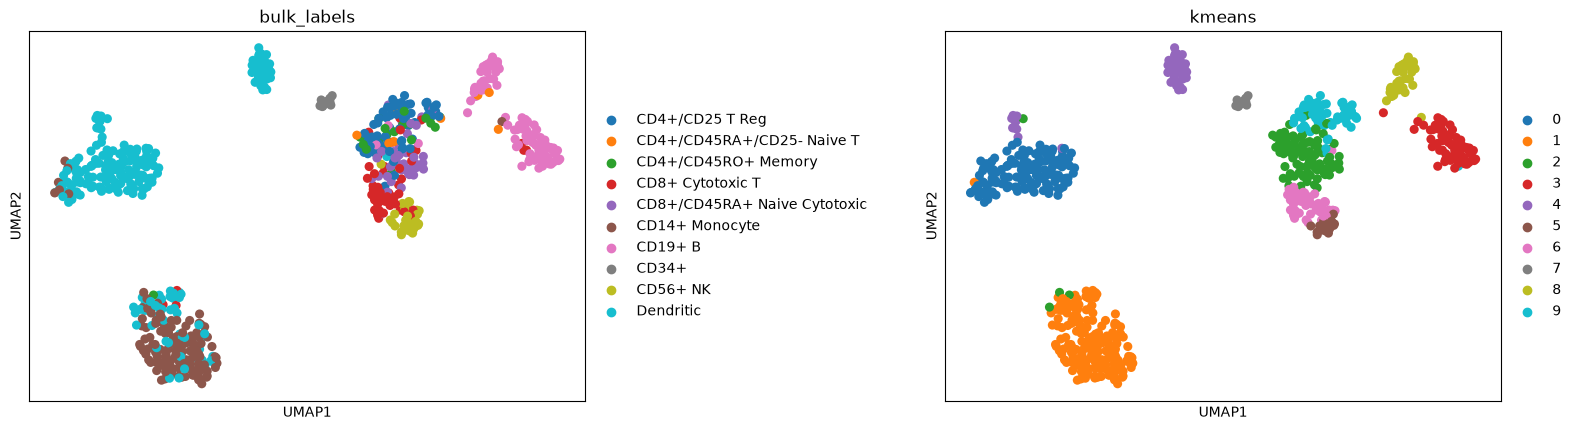

kmeans,0,1,2,3,4,5,6,7,8,9
bulk_labels,,,,,,,,,,
CD4+/CD25 T Reg,0,0,28,0,0,0,0,0,0,40
CD4+/CD45RA+/CD25- Naive T,0,0,3,1,0,0,0,0,2,2
CD4+/CD45RO+ Memory,0,0,8,0,0,0,0,0,0,11
CD8+ Cytotoxic T,0,3,16,3,0,0,29,0,0,3
CD8+/CD45RA+ Naive Cytotoxic,0,0,36,0,0,0,2,0,0,5
CD14+ Monocyte,5,122,1,1,0,0,0,0,0,0
CD19+ B,0,0,2,61,0,0,0,0,30,2
CD34+,0,0,0,0,0,0,0,13,0,0
CD56+ NK,0,0,1,0,0,17,13,0,0,0


In [8]:
sc.pl.umap(adata, color= [config["label_column"], "kmeans"], wspace = 0.5)
pd.crosstab(adata.obs[config["label_column"]], adata.obs["kmeans"])

In [9]:
result = pd.DataFrame({
    "cell_id":adata.obs_names,
    "cluster":km.labels_,
    "method":"kmeans",
    "parameter":k,
    "seed":config["random_state"],
})

In [10]:
result_path  =  ROOT/"results"/"clusters_kmeans.csv"
result_path.parent.mkdir(exist_ok = True)
result.to_csv(result_path, index=False)